# Étude de cas 3 — Jalon 1 : Des descripteurs à la décision

Ce notebook suit le Jalon 1 sur les données demandées par le sujet : **Holter A**. Il transforme chaque fenêtre ECG de 10 secondes en descripteurs, entraîne un MLP à cinq classes, compare trois pertes et règle un seuil d’alerte FA sur validation.

**Protocole de test :** toutes les décisions sont prises avec train et validation. Le test Holter reste fermé jusqu’à l’évaluation finale, après choix du modèle et du seuil. Les anciens résultats enregistrés dans les fichiers de décision venaient du patch B ; ils sont historiques et ne sont pas repris ici.

**Limite du code :** les fiches de jalon et les scripts de démarrage sont présents, mais le notebook général `uc3_demarrage.ipynb` manque. Le détecteur QRS et les descripteurs de base sont donc reconstruits à partir de la description du sujet, et cette hypothèse est signalée dans les résultats. Les signaux sont simulés et n’ont aucune valeur médicale.


## 1. Vérifier l’environnement du notebook

Dans VS Code, sélectionnez le noyau Python de l’environnement `.venv` du projet. Cette cellule affiche les versions des bibliothèques nécessaires ; elle n’installe et ne modifie rien.

In [1]:
# Lire les versions installées sans importer toutes les bibliothèques.
from importlib.metadata import PackageNotFoundError, version
import sys

# Ce chemin doit correspondre à l’environnement choisi comme noyau du notebook dans VS Code.
print('Python utilisé :', sys.executable)
# Afficher la version de chaque bibliothèque requise ou signaler son absence.
for package in ['numpy', 'scipy', 'scikit-learn', 'tensorflow', 'matplotlib']:
    try:
        print(f'{package}: {version(package)}')
    except PackageNotFoundError:
        print(f'{package} : ABSENT')

Python utilisé : /home/mapster/ABOUBAKER/SDIA_PRACTICES/SCHOOL/s3-s4/advanced-ai/USECASE_TP/PRACTICE/.venv/bin/python
numpy: 2.5.3
scipy: 1.18.1
scikit-learn: 1.9.1
tensorflow: 2.21.0
matplotlib: 3.11.2


## 2. Charger les données d’entraînement et de validation

Chaque ligne de `X` représente une fenêtre ECG de 1 250 mesures. Nous chargeons d’abord les classes et les identifiants des patients des ensembles d’entraînement et de validation afin de vérifier les données avant de calculer les descripteurs.

In [2]:
from pathlib import Path
import numpy as np

# Chercher la racine du projet à partir du dossier courant du notebook.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((p for p in candidates if (p / 'data' / 'holter_A').is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Dossier data/holter_A introuvable. Ouvrez le notebook depuis PRACTICE ou un sous-dossier.')
HOLTER_FILE = PROJECT_DIR / 'data' / 'holter_A' / 'uc3_holterA.npz'
if not HOLTER_FILE.exists():
    raise FileNotFoundError(f'Fichier Holter A introuvable : {HOLTER_FILE}')

# Ouvrir le fichier NPZ : il contient les tableaux des trois groupes de patients.
# Ici, ne charger que train et validation ; le test reste réservé à la fin.
A = {}
with np.load(HOLTER_FILE, allow_pickle=False) as holter:
    for split in ['train', 'val']:
        for name in ['X', 'classe', 'fc', 'patient', 'age', 'sexe']:
            A[f'{name}_{split}'] = holter[f'{name}_{split}'].copy()

# Vérifier que les personnes utilisées pour apprendre ne se retrouvent pas en validation.
patients_train = set(np.unique(A['patient_train']))
patients_val = set(np.unique(A['patient_val']))
chevauchement_patients = patients_train & patients_val
assert not chevauchement_patients, f'Patients présents dans train et validation : {chevauchement_patients}'
print('Jeu chargé : Holter A ; patients train et validation disjoints.')

# Vérifier que chaque métadonnée correspond à la bonne fenêtre ECG.
for split in ['train', 'val']:
    split_fr = {'train': 'entraînement', 'val': 'validation'}[split]
    n = len(A[f'classe_{split}'])
    assert A[f'X_{split}'].shape == (n, 1250)
    assert all(len(A[f'{name}_{split}']) == n for name in ['fc', 'patient', 'age', 'sexe'])
    print(f'{split_fr} : {n} fenêtres, {len(np.unique(A[f"patient_{split}"]))} patients, forme {A[f"X_{split}"].shape}')
    # Compter les exemples de chaque rythme dans cet ensemble.
    print('  effectifs par classe :', dict(zip(*np.unique(A[f'classe_{split}'], return_counts=True))))


Jeu chargé : Holter A ; patients train et validation disjoints.
entraînement : 8400 fenêtres, 280 patients, forme (8400, 1250)
  effectifs par classe : {np.int8(0): np.int64(4348), np.int8(1): np.int64(1209), np.int8(2): np.int64(1018), np.int8(3): np.int64(995), np.int8(4): np.int64(830)}
validation : 1800 fenêtres, 60 patients, forme (1800, 1250)
  effectifs par classe : {np.int8(0): np.int64(892), np.int8(1): np.int64(238), np.int8(2): np.int64(292), np.int8(3): np.int64(198), np.int8(4): np.int64(180)}


## Signification des tableaux

- `X_*` : fenêtres ECG brutes (1 250 mesures par fenêtre).
- `classe_*` : classe de rythme à prédire.
- `fc_*`, `age_*`, `sexe_*` : fréquence cardiaque, âge et métadonnées de sexe.
- `patient_*` : identifiant patient, utilisé pour vérifier la séparation des patients entre les ensembles.

L’étape suivante vérifie que les identifiants d’entraînement et de validation sont disjoints, puis construit les descripteurs du signal.

## 3. Observer une fenêtre ECG brute

Avant de calculer des descripteurs, nous traçons un exemple. L’axe horizontal indique le temps en secondes et l’axe vertical l’amplitude mesurée. Les complexes QRS, formes aiguës associées aux battements, sont les événements que le détecteur tente de repérer.

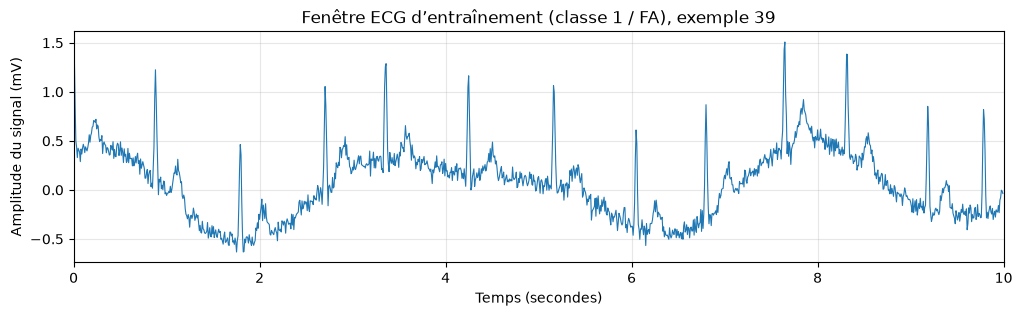

In [3]:
import matplotlib.pyplot as plt

FS = 125  # samples recorded per second, from the case brief
# Trouver la première fenêtre d’entraînement de classe 1 (fibrillation atriale, FA).
sample_idx = int(np.flatnonzero(A['classe_train'] == 1)[0])
# Extraire cette ligne (un signal de 10 secondes) sous forme de nombres décimaux.
signal = A['X_train'][sample_idx].astype(float)
# Convertir les indices 0 à 1 249 en secondes en les divisant par 125.
time_s = np.arange(len(signal)) / FS

# Tracer l’amplitude du signal en fonction du temps.
plt.figure(figsize=(12, 3))
plt.plot(time_s, signal, linewidth=0.8)
plt.title(f'Fenêtre ECG d’entraînement (classe 1 / FA), exemple {sample_idx}')
plt.xlabel('Temps (secondes)')
plt.ylabel('Amplitude du signal (mV)')
plt.xlim(0, 10)
plt.grid(True, alpha=0.3)
plt.show()

**À observer :** la fenêtre contient 1 250 mesures sur 10 secondes. Le détecteur cherche les complexes QRS ; le temps entre deux complexes consécutifs forme un intervalle RR. Les descripteurs résument ces intervalles et d’autres propriétés du signal : le MLP reçoit ainsi quelques nombres plutôt que les 1 250 mesures brutes. Le notebook de démarrage mentionné dans le PDF n’a pas été fourni ; les choix de reconstruction sont donc indiqués explicitement.

## 4. Reconstruire un détecteur QRS simple

La fiche du Jalon 1 décrit un filtre, un calcul d’énergie et une détection de pics. Le script de départ du jalon s’appuie sur le notebook général `uc3_demarrage.ipynb`, absent de l’archive ; le code ci-dessous est donc une reconstruction pédagogique, pas une copie de la méthode officielle. On vérifiera les détections en les comparant à la fréquence cardiaque fournie. Les signaux sont simulés ; ce détecteur n’a pas d’usage médical.

1. Garder les fréquences entre 5 et 18 Hz pour faire ressortir les QRS.
2. Mettre au carré les variations puis lisser l’énergie sur 0,12 seconde.
3. Détecter les pics d’énergie séparés d’au moins 0,25 seconde.
4. Replacer chaque candidat sur le pic le plus marqué du signal filtré voisin.


In [4]:
# SciPy fournit le filtre numérique et les fonctions de détection de pics.
from scipy.signal import butter, sosfiltfilt, find_peaks

def detect_qrs(window, fs=125):
    # Vérifier que le signal est un tableau numérique à une dimension.
    window = np.asarray(window, dtype=float)

    # Filtre passe-bande : conserver les fréquences utiles pour faire ressortir les QRS.
    sos = butter(3, [5, 18], btype='bandpass', fs=fs, output='sos')
    filtered = sosfiltfilt(sos, window)

    # Après mise au carré, les variations rapides deviennent de fortes valeurs positives.
    # np.diff calcule les variations entre mesures consécutives.
    derivative = np.diff(filtered, prepend=filtered[0])
    # Le carré supprime le signe et fait ressortir les variations rapides.
    energy = derivative ** 2
    # Moyenner l’énergie sur environ 0,12 seconde pour lisser les petites fluctuations.
    smooth_n = max(1, round(0.12 * fs))
    energy_smooth = np.convolve(energy, np.ones(smooth_n) / smooth_n, mode='same')

    # La MAD est moins influencée que l’écart-type par quelques pics d’énergie très élevés.
    med = np.median(energy_smooth)
    mad = np.median(np.abs(energy_smooth - med))
    threshold = med + 4 * mad
    # Détecter les pics d’énergie en les espaçant d’au moins 0,25 seconde.
    candidates, _ = find_peaks(
        energy_smooth,
        distance=round(0.25 * fs),
        height=threshold,
        prominence=max(4 * mad, np.finfo(float).eps),
    )

    # Replacer chaque candidat sur le point le plus marqué du signal ECG filtré.
    # Chercher le point ECG le plus marqué dans une fenêtre de ±0,08 seconde.
    radius = round(0.08 * fs)
    qrs_peaks = []
    for candidate in candidates:
        left = max(0, candidate - radius)
        right = min(len(filtered), candidate + radius + 1)
        qrs_peaks.append(left + int(np.argmax(np.abs(filtered[left:right]))))

    # Renvoyer les positions QRS affinées, les pics d’énergie et les signaux à tracer.
    return np.asarray(qrs_peaks, dtype=int), candidates, filtered, energy_smooth

Complexes QRS détectés : 13
Intervalles RR (secondes) : [0.848 0.912 0.912 0.648 0.896 0.92  0.88  0.752 0.848 0.664 0.872 0.6  ]


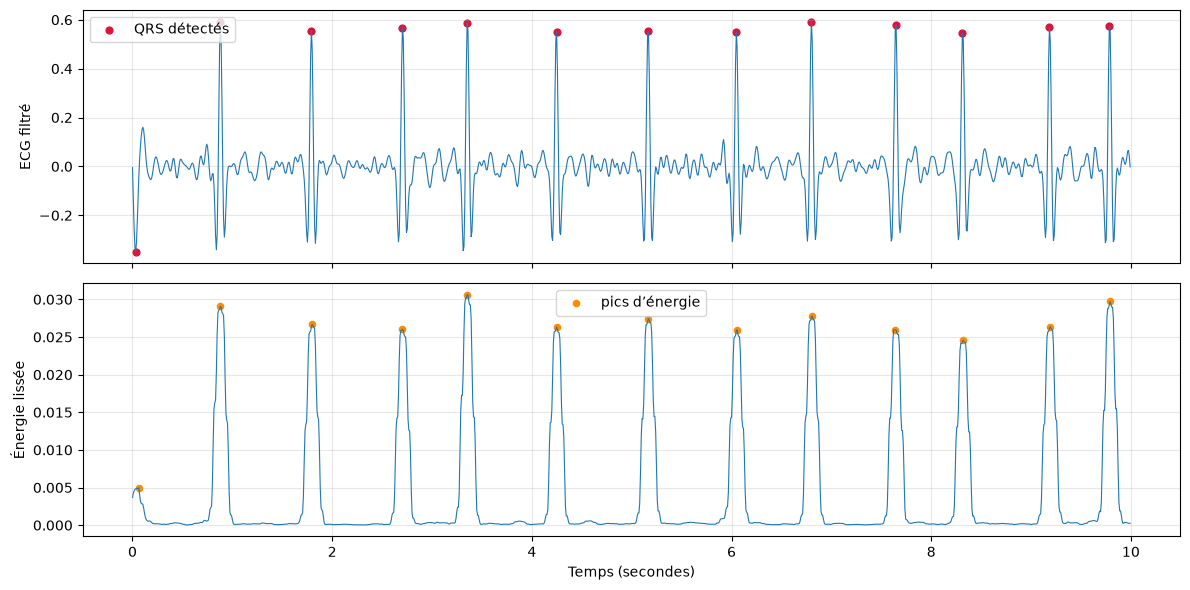

In [5]:
# Appliquer le détecteur à la fenêtre de 10 secondes choisie.
qrs_peaks, energy_peaks, filtered, energy_smooth = detect_qrs(signal, FS)
# La distance en secondes entre deux QRS consécutifs forme un intervalle RR.
rr_s = np.diff(qrs_peaks) / FS
print('Complexes QRS détectés :', len(qrs_peaks))
print('Intervalles RR (secondes) :', np.round(rr_s, 3))

# Panneau du haut : ECG filtré et repères rouges aux positions QRS affinées.
# Panneau du bas : énergie lissée et repères orange aux pics candidats.
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(time_s, filtered, linewidth=0.8)
axes[0].scatter(qrs_peaks / FS, filtered[qrs_peaks], color='crimson', s=24, label='QRS détectés')
axes[0].set_ylabel('ECG filtré')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(time_s, energy_smooth, linewidth=0.8)
axes[1].scatter(energy_peaks / FS, energy_smooth[energy_peaks], color='darkorange', s=20, label='pics d’énergie')
axes[1].set(xlabel='Temps (secondes)', ylabel='Énergie lissée')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Transformer les intervalles RR en descripteurs

Cette reconstruction explicite utilise huit statistiques RR (moyenne, écart-type, médiane, minimum, maximum, étendue, RMSSD et pNN50), puis ajoute l’énergie du signal filtré, l’âge et le code de sexe : 11 valeurs au total. Le RMSSD résume les variations entre intervalles RR voisins ; le pNN50 est la proportion de ces variations qui dépasse 0,05 seconde. Le PDF ne donne pas les noms officiels des onze descripteurs : cette liste est une hypothèse documentée, à remplacer si le notebook de démarrage est retrouvé. La fréquence `fc` fournie n’est pas utilisée comme entrée dans cette reconstruction.

Avec moins de deux complexes QRS détectés, aucun intervalle RR ne peut être calculé ; les statistiques RR sont alors déclarées manquantes et la fenêtre est comptée comme un échec grossier du détecteur.

In [6]:
# Les noms de descripteurs suivent l’ordre des valeurs renvoyées ci-dessous.
FEATURE_NAMES = [
    'rr_moy_s', 'rr_ecart_type_s', 'rr_mediane_s', 'rr_min_s',
    'rr_max_s', 'rr_etendue_s', 'rr_rmssd_s', 'rr_pnn50_proportion',
    'energie_signal_filtre', 'age_ans', 'code_sexe'
]

def describe_window(window, age, sex, fs=125):
    # Détecter les battements puis convertir les écarts entre positions en secondes.
    qrs_peaks, _, filtered, _ = detect_qrs(window, fs)
    rr = np.diff(qrs_peaks) / fs

    # Sans deux battements détectés, aucun RR n’existe ; marquer les statistiques RR manquantes.
    if len(rr) == 0:
        rr_stats = [np.nan] * 8
    else:
        # Comparer les intervalles RR voisins pour mesurer l’irrégularité entre battements.
        changes = np.diff(rr)
        rmssd = np.sqrt(np.mean(changes ** 2)) if len(changes) else np.nan
        pnn50 = np.mean(np.abs(changes) > 0.05) if len(changes) else np.nan
        rr_stats = [
            np.mean(rr), np.std(rr), np.median(rr), np.min(rr),
            np.max(rr), np.ptp(rr), rmssd, pnn50
        ]

    # La moyenne du signal filtré au carré sert de descripteur d’énergie.
    signal_energy = np.mean(filtered ** 2)
    # Réunir les 8 statistiques RR, l’énergie, l’âge et le sexe pour obtenir 11 valeurs.
    features = np.asarray(rr_stats + [signal_energy, float(age), float(sex)], dtype=float)
    return features, len(qrs_peaks)

# Calculer une ligne de 11 descripteurs pour chaque fenêtre d’entraînement et de validation.
FA = {}
qrs_counts = {}
for split in ['train', 'val']:
    split_fr = {'train': 'entraînement', 'val': 'validation'}[split]
    rows, counts = [], []
    for i, window in enumerate(A[f'X_{split}']):
        # Utiliser l’âge et le sexe associés à cette même fenêtre.
        row, n_peaks = describe_window(window, A[f'age_{split}'][i], A[f'sexe_{split}'][i], FS)
        rows.append(row)
        counts.append(n_peaks)
    FA[split] = np.vstack(rows)
    qrs_counts[split] = np.asarray(counts)
    # Un échec grossier signifie moins de deux pics détectés, donc aucun intervalle RR.
    failures = int(np.sum(qrs_counts[split] < 2))
    print(f'{split_fr} : matrice de descripteurs={FA[split].shape} ; échecs QRS (<2 pics)={failures}')

# Remplacer d’éventuelles statistiques indéfinies par la médiane calculée sur train.
# On réutilise ces médianes pour validation afin de ne pas apprendre sur elle.
medians = np.nanmedian(FA['train'], axis=0)
medians = np.nan_to_num(medians, nan=0.0)
for split in ['train', 'val']:
    missing = np.isnan(FA[split])
    if missing.any():
        FA[split] = np.where(missing, medians, FA[split])
        print(f'{split} : {missing.sum()} valeurs manquantes remplacées par les médianes train.')

# Afficher un exemple sous forme de paires nom/valeur pour interpréter les entrées.
print('Exemple de ligne de descripteurs :')
for name, value in zip(FEATURE_NAMES, FA['train'][sample_idx]):
    print(f'  {name}: {value:.4f}')

entraînement : matrice de descripteurs=(8400, 11) ; échecs QRS (<2 pics)=0


validation : matrice de descripteurs=(1800, 11) ; échecs QRS (<2 pics)=0
Exemple de ligne de descripteurs :
  rr_moy_s: 0.8127
  rr_ecart_type_s: 0.1106
  rr_mediane_s: 0.8600
  rr_min_s: 0.6000
  rr_max_s: 0.9200
  rr_etendue_s: 0.3200
  rr_rmssd_s: 0.1690
  rr_pnn50_proportion: 0.7273
  energie_signal_filtre: 0.0150
  age_ans: 59.0000
  code_sexe: 1.0000


## 6. Normaliser les descripteurs

Les descripteurs ont des unités et des échelles différentes : secondes, énergie du signal, âge et code de sexe. `StandardScaler` soustrait à chaque valeur la moyenne calculée sur l’entraînement, puis la divise par l’écart-type correspondant. Nous ajustons le scaler uniquement sur l’entraînement et réutilisons ces mêmes paramètres pour la validation. Ainsi, les données de validation n’influencent pas le prétraitement.

In [7]:
from sklearn.preprocessing import StandardScaler

# Ajuster le scaler et calculer la moyenne et l’écart-type sur l’entraînement seulement.
norm = StandardScaler()
XF = {}
XF['train'] = norm.fit_transform(FA['train'])

# Réutiliser pour la validation le scaler de l’entraînement, sans en ajuster un autre.
XF['val'] = norm.transform(FA['val'])

print('Dimensions après normalisation :', XF['train'].shape, XF['val'].shape)
print('Moyennes des descripteurs d’entraînement (proches de 0) :', np.round(XF['train'].mean(axis=0), 3))
print('Écarts-types des descripteurs d’entraînement (proches de 1) :', np.round(XF['train'].std(axis=0), 3))

Dimensions après normalisation : (8400, 11) (1800, 11)


Moyennes des descripteurs d’entraînement (proches de 0) : [ 0. -0.  0. -0. -0.  0.  0.  0.  0. -0. -0.]
Écarts-types des descripteurs d’entraînement (proches de 1) : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 7. Construire et entraîner le MLP de référence

L’architecture comprend 64 unités ReLU, un dropout de 20 %, 32 unités ReLU, puis cinq sorties softmax. Les étiquettes sont des identifiants entiers de classe ; nous utilisons l’entropie croisée catégorielle sparse et des poids de classe calculés uniquement avec les étiquettes d’entraînement. Une graine fixe facilite la reproduction de l’expérience.

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fixer les graines aléatoires pour retrouver la même initialisation à chaque exécution.
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Compter les exemples d’entraînement de chacune des cinq classes de rythme.
y_train = A['classe_train'].astype(int)
class_counts = np.bincount(y_train, minlength=5)
n_train = len(y_train)
n_classes = 5

# Appliquer la formule du sujet : lignes totales / (classes × lignes de la classe).
class_weight = {k: n_train / (n_classes * class_counts[k]) for k in range(n_classes)}
print('Effectifs des classes dans l’entraînement :', class_counts.tolist())
print('Poids des classes :', {k: round(v, 3) for k, v in class_weight.items()})

def build_mlp(input_dim, n_classes=5):
    # Chaque entrée correspond à l’un des 11 descripteurs.
    inputs = keras.Input(shape=(input_dim,))

    # Première couche dense : chaque neurone reçoit les 11 descripteurs.
    x = layers.Dense(64, activation='relu')(inputs)

    # Le dropout masque aléatoirement 20 % des activations à l’entraînement pour limiter le surapprentissage.
    x = layers.Dropout(0.2)(x)

    # La deuxième couche cachée combine les motifs de la première couche.
    x = layers.Dense(32, activation='relu')(x)

    # Les cinq valeurs softmax représentent les scores probabilistes des cinq rythmes.
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    model = keras.Model(inputs, outputs)

    # Adam ajuste les poids ; l’entropie croisée sparse attend les identifiants 0 à 4.
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

# Créer le réseau avec le nombre de descripteurs de la matrice d’entrée.
baseline = build_mlp(input_dim=XF['train'].shape[1])
baseline.summary()

I0000 00:00:1793699461.793855   59881 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793699461.835490   59881 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Effectifs des classes dans l’entraînement : [4348, 1209, 1018, 995, 830]
Poids des classes : {0: np.float64(0.386), 1: np.float64(1.39), 2: np.float64(1.65), 3: np.float64(1.688), 4: np.float64(2.024)}


I0000 00:00:1793699463.041879   59881 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1793699463.178901   59881 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 11)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,013 (11.77 KB)

 Trainable params: 3,013 (11.77 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Entraîner sur les descripteurs ; class_weight augmente le coût des erreurs des classes rares.
history = baseline.fit(
    XF['train'],
    y_train,
    epochs=60,
    batch_size=64,
    class_weight=class_weight,
    validation_data=(XF['val'], A['classe_val'].astype(int)),
    verbose=0,
)

# Afficher la perte et l’exactitude finales de l’entraînement et de la validation.
print('Perte finale d’entraînement :', round(history.history['loss'][-1], 4))
print('Exactitude finale d’entraînement :', round(history.history['accuracy'][-1], 4))
print('Perte finale de validation :', round(history.history['val_loss'][-1], 4))
print('Exactitude finale de validation :', round(history.history['val_accuracy'][-1], 4))

Perte finale d’entraînement : 0.0886
Exactitude finale d’entraînement : 0.9577
Perte finale de validation : 0.1394
Exactitude finale de validation : 0.9444


## 8. Examiner les erreurs de validation

La matrice de confusion compare les classes réelles (lignes) aux classes prédites (colonnes). Le rappel par classe indique la proportion des fenêtres de cette classe correctement retrouvées. Ces résultats concernent la validation et servent aux choix du modèle.

In [10]:
from sklearn.metrics import confusion_matrix, recall_score, f1_score

# Prédire un score par classe puis choisir le plus élevé pour la décision à cinq classes.
p_val = baseline.predict(XF['val'], verbose=0)
pred_val = np.argmax(p_val, axis=1)
y_val = A['classe_val'].astype(int)

# Garder l’ordre des classes 0 à 4 pour lire facilement les lignes et colonnes.
labels = np.arange(5)
cm = confusion_matrix(y_val, pred_val, labels=labels)
print('Matrice de confusion (lignes=réel, colonnes=prédit) :\n', cm)

# Calculer le rappel de chaque classe ; zero_division gère les classes absentes.
recalls = recall_score(y_val, pred_val, labels=labels, average=None, zero_division=0)
for class_id, recall in zip(labels, recalls):
    print(f'rappel de la classe {class_id} : {recall:.3f}')
print('F1 macro de validation :', round(f1_score(y_val, pred_val, average='macro'), 3))

Matrice de confusion (lignes=réel, colonnes=prédit) :
 [[811  47  12  18   4]
 [  7 228   0   0   3]
 [  5   0 286   0   1]
 [  1   0   0 197   0]
 [  2   0   0   0 178]]
rappel de la classe 0 : 0.909
rappel de la classe 1 : 0.958
rappel de la classe 2 : 0.979
rappel de la classe 3 : 0.995
rappel de la classe 4 : 0.989
F1 macro de validation : 0.946


## 9. Vérifier les estimations QRS avec la fréquence cardiaque fournie

Chaque fenêtre possède une fréquence cardiaque `fc`. Nous la comparons à l’estimation `60 / moyenne(RR)` comme contrôle de cohérence. Ce n’est pas une annotation de référence des battements : des méthodes de moyenne différentes, des extrasystoles ou des erreurs de détection peuvent expliquer les écarts. Une fenêtre est signalée si l’écart dépasse 15 battements/minute ou 20 % de la valeur fournie ; quelques exemples des ensembles d’entraînement et de validation sont ensuite tracés.

entraînement : 207 / 8400 fenêtres à examiner visuellement
  ligne 2259 : estimée~85.9 bpm, fournie=37.2, écart=48.7
  ligne 5284 : estimée~84.0 bpm, fournie=39.7, écart=44.3
  ligne 2263 : estimée~82.2 bpm, fournie=38.8, écart=43.3
  ligne 765 : estimée~76.4 bpm, fournie=35.1, écart=41.3
  ligne 1772 : estimée~77.2 bpm, fournie=36.1, écart=41.1
validation : 38 / 1800 fenêtres à examiner visuellement
  ligne 507 : estimée~77.8 bpm, fournie=36.7, écart=41.0
  ligne 1499 : estimée~62.6 bpm, fournie=39.1, écart=23.5
  ligne 702 : estimée~61.2 bpm, fournie=38.2, écart=22.9
  ligne 70 : estimée~57.4 bpm, fournie=35.9, écart=21.5
  ligne 1411 : estimée~75.3 bpm, fournie=56.5, écart=18.8


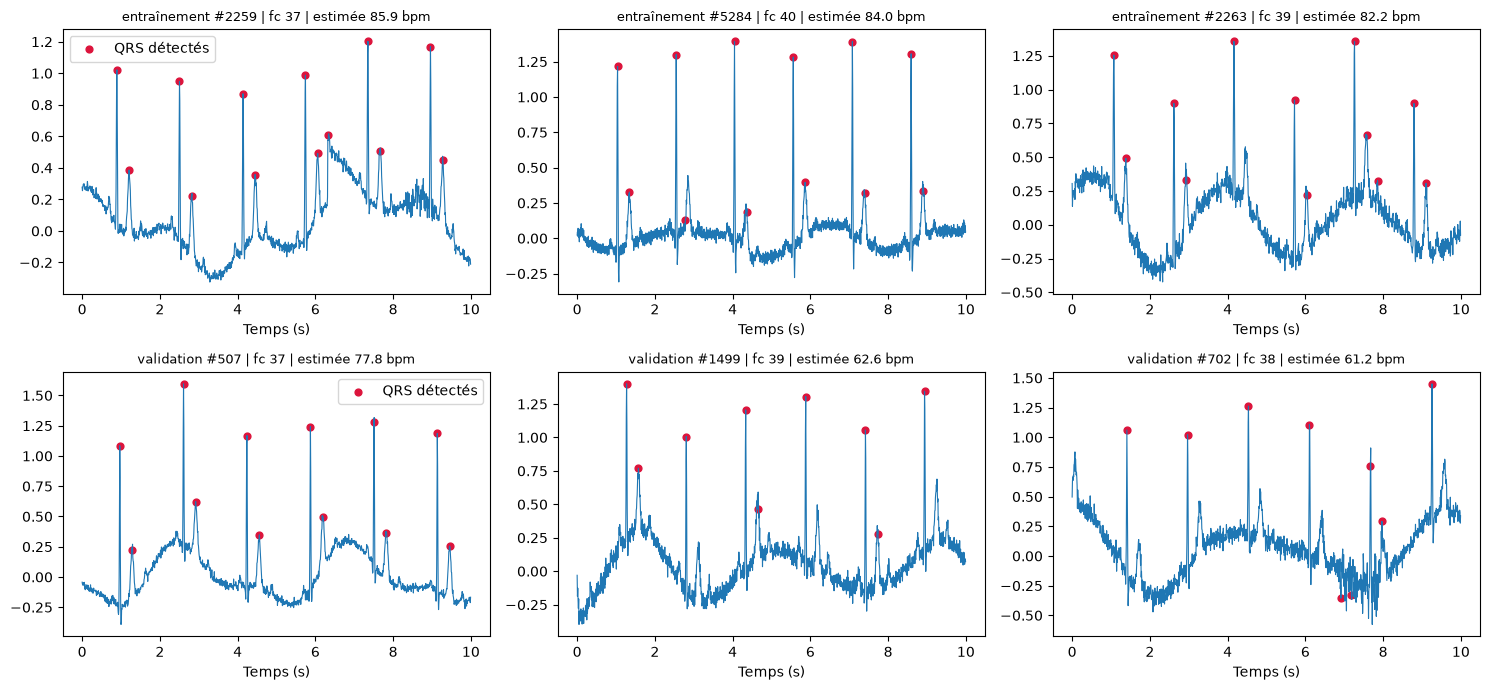

In [11]:
# Comparer la fréquence moyenne issue des intervalles RR à la métadonnée fournie.
qrs_review = {}
for split in ['train', 'val']:
    split_fr = {'train': 'entraînement', 'val': 'validation'}[split]
    # 60 secondes par minute divisées par le RR moyen donnent une fréquence approximative.
    estimated_bpm = 60.0 / FA[split][:, 0]
    supplied_bpm = A[f'fc_{split}'].astype(float)
    difference = np.abs(estimated_bpm - supplied_bpm)
    # Ce seuil sert à signaler des cas à examiner, pas à définir un échec certain.
    flags = (difference > 15) | (difference / np.maximum(supplied_bpm, 1) > 0.20)
    qrs_review[split] = (estimated_bpm, supplied_bpm, difference, flags)
    print(f'{split_fr} : {flags.sum()} / {len(flags)} fenêtres à examiner visuellement')
    worst = np.argsort(difference)[-5:][::-1]
    for i in worst:
        print(f'  ligne {i} : estimée~{estimated_bpm[i]:.1f} bpm, fournie={supplied_bpm[i]:.1f}, écart={difference[i]:.1f}')

# Tracer jusqu’à trois fenêtres les plus divergentes dans l’entraînement et la validation.
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row_num, split in enumerate(['train', 'val']):
    split_fr = {'train': 'entraînement', 'val': 'validation'}[split]
    worst_rows = np.argsort(qrs_review[split][2])[-3:][::-1]
    for col_num, row in enumerate(worst_rows):
        ax = axes[row_num, col_num]
        peaks, _, _, _ = detect_qrs(A[f'X_{split}'][row], FS)
        seconds = np.arange(A[f'X_{split}'].shape[1]) / FS
        ax.plot(seconds, A[f'X_{split}'][row], linewidth=0.8)
        ax.scatter(peaks / FS, A[f'X_{split}'][row][peaks], color='crimson', s=24, label='QRS détectés')
        ax.set_title(f'{split_fr} #{row} | fc {A[f"fc_{split}"][row]:.0f} | estimée {qrs_review[split][0][row]:.1f} bpm', fontsize=9)
        ax.set_xlabel('Temps (s)')
        if col_num == 0:
            ax.legend()
plt.tight_layout(); plt.show()


**Interprétation :** un écart important signifie « examiner cette fenêtre », et non « le détecteur est forcément erroné ». Le PDF ne fournit pas les positions de battements de référence, et la fréquence cardiaque peut avoir été calculée autrement.

## 10. Comparer trois fonctions de perte avec les mêmes onze descripteurs

Les trois expériences utilisent les mêmes données, les mêmes onze descripteurs, la même architecture et les mêmes paramètres d’entraînement ; seule la fonction de perte change. L’entropie croisée simple traite les exemples de la même façon, l’entropie pondérée augmente le poids des classes rares, et la perte focale (`gamma=2`) insiste davantage sur les exemples difficiles. Nous comparons les modèles avec le F1 macro de validation, qui donne le même poids aux cinq classes. Le modèle ayant le F1 macro de validation le plus élevé est retenu pour la suite ; le test reste à part.

In [12]:
# Cette fonction crée le même petit MLP pour comparer équitablement les pertes.
def make_mlp(input_width, loss_kind='weighted_ce'):
    model = keras.Sequential([
        layers.Input(shape=(input_width,)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.20),
        layers.Dense(32, activation='relu'),
        layers.Dense(5, activation='softmax')
    ])
    if loss_kind == 'focal':
        # La perte focale attend des cibles one-hot plutôt que des identifiants de classe.
        loss = keras.losses.CategoricalFocalCrossentropy(gamma=2.0)
    else:
        loss = keras.losses.SparseCategoricalCrossentropy()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss=loss, metrics=['accuracy'])
    return model

from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight

# Équilibrer approximativement les classes : poids plus grands pour les classes rares.
class_ids = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=class_ids, y=y_train)
CLASS_WEIGHTS = dict(zip(class_ids.tolist(), weights.tolist()))
print('Poids des classes d’entraînement :', {k: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

# Les étiquettes one-hot sont utilisées uniquement avec la perte focale.
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=5)
y_val_onehot = keras.utils.to_categorical(y_val, num_classes=5)

loss_results = {}
loss_models = {}
for loss_kind in ['ordinary_ce', 'weighted_ce', 'focal']:
    loss_kind_fr = {'ordinary_ce': 'entropie_croisee_simple', 'weighted_ce': 'entropie_croisee_ponderee', 'focal': 'perte_focale'}[loss_kind]
    keras.utils.set_random_seed(SEED)
    model = make_mlp(XF['train'].shape[1], loss_kind)
    fit_args = {'class_weight': CLASS_WEIGHTS} if loss_kind == 'weighted_ce' else {}
    train_target = y_train_onehot if loss_kind == 'focal' else y_train
    val_target = y_val_onehot if loss_kind == 'focal' else y_val
    hist = model.fit(XF['train'], train_target, validation_data=(XF['val'], val_target),
                     epochs=60, batch_size=64, verbose=0, **fit_args)
    probabilities = model.predict(XF['val'], verbose=0)
    predictions = probabilities.argmax(axis=1)
    loss_results[loss_kind] = {
        'val_accuracy': accuracy_score(y_val, predictions),
        'macro_f1': f1_score(y_val, predictions, average='macro', zero_division=0),
        'recall': recall_score(y_val, predictions, labels=np.arange(5), average=None, zero_division=0),
        'val_loss': float(hist.history['val_loss'][-1]),
        'probabilities': probabilities
    }
    loss_models[loss_kind] = model
    print(f'{loss_kind_fr} : exactitude_val={loss_results[loss_kind]["val_accuracy"]:.3f}, '
          f'F1_macro={loss_results[loss_kind]["macro_f1"]:.3f}, '
          f'perte_val={loss_results[loss_kind]["val_loss"]:.3f}, '
          f'rappel={np.round(loss_results[loss_kind]["recall"], 3)}')


Poids des classes d’entraînement : {0: 0.386, 1: 1.39, 2: 1.65, 3: 1.688, 4: 2.024}


entropie_croisee_simple : exactitude_val=0.972, F1_macro=0.970, perte_val=0.102, rappel=[0.976 0.937 0.976 0.99  0.967]


entropie_croisee_ponderee : exactitude_val=0.944, F1_macro=0.946, perte_val=0.139, rappel=[0.909 0.958 0.979 0.995 0.989]


perte_focale : exactitude_val=0.969, F1_macro=0.968, perte_val=0.010, rappel=[0.975 0.937 0.979 0.995 0.939]


**À retenir :** une seule métrique ne suffit pas. L’entropie croisée simple obtient ici le meilleur F1 macro de validation (`0,970`), devant la perte focale (`0,968`) et l’entropie pondérée (`0,946`), donc elle est retenue selon la règle annoncée. La validation Holter A contient 238 fenêtres de classe 1 ; le rappel de cette classe dépend donc de ces 238 exemples, et non de six. Il faut lire aussi le rappel par classe et la matrice de confusion pour voir les différences entre classes.

## 11. Ajouter des familles de descripteurs et faire des ablations

La liste exacte du notebook de démarrage manquant est inconnue. Les descripteurs supplémentaires sont donc une reconstruction documentée : irrégularité des intervalles RR, amplitude et largeur des complexes QRS, et énergie dans trois bandes de fréquences. Une ablation retire une famille à la fois pour mesurer son effet sur cette validation.

In [13]:
# Calculer les familles de descripteurs supplémentaires à partir du signal et des QRS.
from scipy.signal import peak_widths, peak_prominences, butter, sosfiltfilt

EXTRA_GROUP_NAMES = {
    'irregularity': ['rr_cv', 'rr_mad', 'rr_sdsd', 'poincare_sd1', 'poincare_sd2'],
    'qrs_shape': ['qrs_amp_mean', 'qrs_amp_std', 'qrs_width_mean_s', 'qrs_width_std_s'],
    'band_energy': ['energy_0p5_5', 'energy_5_18', 'energy_18_40']
}

def extra_descriptors(window, fs=125):
    # Réutiliser le détecteur des descripteurs de base pour garder la même chaîne de traitement.
    peaks, _, filtered, _ = detect_qrs(window, fs)
    rr = np.diff(peaks) / fs
    if len(rr) >= 2:
        changes = np.diff(rr)
        rr_mean = np.mean(rr)
        cv = np.std(rr) / rr_mean if rr_mean else 0.0
        rr_mad = np.median(np.abs(rr - np.median(rr)))
        sdsd = np.std(changes) if len(changes) else 0.0
        sd1 = np.sqrt(max(0, 0.5 * np.var(changes))) if len(changes) else 0.0
        sd2 = np.sqrt(max(0, 2 * np.var(rr) - 0.5 * np.var(changes))) if len(changes) else 0.0
    else:
        cv = rr_mad = sdsd = sd1 = sd2 = 0.0

    # Mesurer l’amplitude sur le signal filtré et la largeur à mi-proéminence.
    if len(peaks):
        # Écarter des largeurs les détections sans proéminence mesurable.
        # Ignorer l’avertissement SciPy pour les pics sans proéminence mesurable.
        import warnings
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='some peaks have a prominence of 0')
            prominences = peak_prominences(filtered, peaks)[0]
        measurable = prominences > 0
        valid_peaks = peaks[measurable]
        if len(valid_peaks):
            amplitudes = filtered[valid_peaks]
            widths = peak_widths(filtered, valid_peaks, rel_height=0.5)[0] / fs
            amp_mean, amp_std = np.mean(amplitudes), np.std(amplitudes)
            width_mean, width_std = np.mean(widths), np.std(widths)
        else:
            amp_mean = amp_std = width_mean = width_std = 0.0
    else:
        amp_mean = amp_std = width_mean = width_std = 0.0

    # Calculer l’énergie moyenne au carré dans trois bandes de fréquences.
    energies = []
    for low, high in [(0.5, 5), (5, 18), (18, 40)]:
        sos = butter(3, [low, high], btype='bandpass', fs=fs, output='sos')
        band = sosfiltfilt(sos, window)
        energies.append(np.mean(band ** 2))
    return np.array([cv, rr_mad, sdsd, sd1, sd2, amp_mean, amp_std, width_mean, width_std, *energies])

EXTRA_FEATURE_NAMES = sum(EXTRA_GROUP_NAMES.values(), [])
EXTRA = {}
for split in ['train', 'val']:
    split_fr = {'train': 'entraînement', 'val': 'validation'}[split]
    EXTRA[split] = np.vstack([extra_descriptors(x, FS) for x in A[f'X_{split}']])
    print(f'{split_fr} : matrice des descripteurs supplémentaires {EXTRA[split].shape}')

# Réunir les 11 entrées initiales et les nouvelles familles, puis ajuster un scaler sur l’entraînement.
X_all_raw = {split: np.column_stack([FA[split], EXTRA[split]]) for split in ['train', 'val']}
all_scaler = StandardScaler().fit(X_all_raw['train'])
X_all = {split: all_scaler.transform(X_all_raw[split]) for split in ['train', 'val']}

# Comparer tous les descripteurs aux variantes privées d’une famille.
GROUP_COLS = {
    'irregularity': list(range(11, 16)),
    'qrs_shape': list(range(16, 20)),
    'band_energy': list(range(20, 23))
}

def train_eval_features(columns, experiment_name):
    keras.utils.set_random_seed(SEED)
    model = make_mlp(len(columns), 'weighted_ce')
    model.fit(X_all['train'][:, columns], y_train, epochs=60, batch_size=64,
              class_weight=CLASS_WEIGHTS, verbose=0)
    probs = model.predict(X_all['val'][:, columns], verbose=0)
    pred = probs.argmax(axis=1)
    return model, probs, {
        'name': experiment_name,
        'val_accuracy': accuracy_score(y_val, pred),
        'macro_f1': f1_score(y_val, pred, average='macro', zero_division=0),
        'recall': recall_score(y_val, pred, labels=np.arange(5), average=None, zero_division=0)
    }

feature_results = {}
feature_models = {}
all_columns = list(range(23))
feature_models['full'], _, feature_results['full'] = train_eval_features(all_columns, 'full')
for removed_group, columns_to_remove in GROUP_COLS.items():
    kept = [i for i in all_columns if i not in columns_to_remove]
    feature_models[f'without_{removed_group}'], _, feature_results[f'without_{removed_group}'] = train_eval_features(kept, f'without_{removed_group}')

for name, result in feature_results.items():
    nom_fr = {'full': 'complets', 'without_irregularity': 'sans_irrégularité_RR', 'without_qrs_shape': 'sans_forme_QRS', 'without_band_energy': 'sans_énergie_par_bande'}[name]
    print(f'{nom_fr} : exactitude_val={result["val_accuracy"]:.3f}, F1_macro={result["macro_f1"]:.3f}, rappel={np.round(result["recall"], 3)}')


entraînement : matrice des descripteurs supplémentaires (8400, 12)


validation : matrice des descripteurs supplémentaires (1800, 12)


complets : exactitude_val=0.957, F1_macro=0.957, rappel=[0.942 0.958 0.962 0.99  0.989]
sans_irrégularité_RR : exactitude_val=0.953, F1_macro=0.953, rappel=[0.933 0.945 0.983 0.99  0.978]
sans_forme_QRS : exactitude_val=0.963, F1_macro=0.964, rappel=[0.943 0.971 0.979 0.99  0.994]
sans_énergie_par_bande : exactitude_val=0.961, F1_macro=0.963, rappel=[0.939 0.966 0.983 0.995 0.989]


**Interprétation des ablations :** comparer le jeu `full` aux jeux `without_...`. Si le retrait d’une famille améliore le score de validation, elle peut ajouter du bruit ou la petite validation peut être instable. Cela ne prouve pas que cette famille est inutile en général.

## 12. Choisir un seuil d’alerte FA sur la validation

Pour la classification à cinq classes, `argmax` choisit la plus grande probabilité. Pour une alerte binaire de fibrillation atriale (FA), nous comparons plutôt la probabilité de la classe 1 à un seuil. Celui-ci est choisi au 95e percentile des scores des fenêtres qui ne sont pas des FA. Il s’agit d’un point de fonctionnement pédagogique calculé sur la validation, et non d’une recommandation clinique.

In [14]:
# Choisir la perte avec le meilleur F1 macro de validation selon une règle explicite.
selected_loss = max(loss_results, key=lambda name: loss_results[name]['macro_f1'])
selected_model = loss_models[selected_loss]
selected_probabilities = loss_results[selected_loss]['probabilities']
non_af_scores = selected_probabilities[y_val != 1, 1]
af_scores = selected_probabilities[y_val == 1, 1]
# Le 95e percentile des scores non-FA vise environ 95 % de spécificité sur la validation.
af_threshold = float(np.quantile(non_af_scores, 0.95))
alert_val = selected_probabilities[:, 1] >= af_threshold
actual_af = y_val == 1
specificity = np.mean(~alert_val[y_val != 1])
sensitivity = np.mean(alert_val[y_val == 1]) if np.any(y_val == 1) else np.nan
libelle_perte = {'ordinary_ce': 'entropie croisée simple', 'weighted_ce': 'entropie croisée pondérée', 'focal': 'perte focale'}[selected_loss]
print('Perte retenue selon le F1 macro de validation :', libelle_perte)
print(f'Seuil de probabilité FA : {af_threshold:.4f}')
print(f'Spécificité en validation : {specificity:.3f} ({np.sum(~alert_val[y_val != 1])}/{np.sum(y_val != 1)} fenêtres non-FA sans alerte)')
print(f'Sensibilité en validation : {sensitivity:.3f} ({np.sum(alert_val[y_val == 1])}/{np.sum(y_val == 1)} fenêtres FA alertées)')
print('Scores FA des fenêtres de validation :', np.round(af_scores, 3))


Perte retenue selon le F1 macro de validation : entropie croisée simple
Seuil de probabilité FA : 0.1057
Spécificité en validation : 0.949 (1483/1562 fenêtres non-FA sans alerte)
Sensibilité en validation : 0.979 (233/238 fenêtres FA alertées)
Scores FA des fenêtres de validation : [0.987 0.122 1.    0.99  1.    1.    0.905 0.973 1.    0.867 1.    1.
 1.    0.995 1.    1.    1.    0.97  0.997 1.    0.988 0.997 0.206 0.966
 1.    0.012 0.811 0.093 0.997 0.979 0.961 1.    0.832 1.    1.    1.
 1.    1.    0.994 0.848 1.    1.    1.    1.    0.139 0.945 0.998 0.926
 1.    1.    0.993 1.    1.    0.993 1.    0.926 0.997 1.    1.    1.
 0.999 1.    1.    1.    1.    1.    1.    1.    0.769 0.955 0.873 0.683
 0.731 0.914 0.779 0.685 0.798 0.997 0.278 0.994 1.    0.992 0.85  0.987
 1.    0.844 0.506 1.    0.96  1.    0.305 0.281 1.    1.    1.    1.
 0.997 0.996 0.999 0.967 0.996 0.721 0.961 1.    0.992 1.    0.975 0.978
 1.    0.995 0.997 0.997 0.895 0.    1.    1.    0.987 1.    1.    0.998

## 13. Vérifier les calculs à la main

Ces petits calculs relient les formules aux sorties du modèle. Les cinq probabilités ci-dessous sont un exemple inventé pour l’exercice ; elles ne proviennent pas du jeu de données.

In [15]:
# Exemple : la vraie classe est 1, mais le modèle ne lui attribue qu’un score de 0,30.
example_probabilities = np.array([0.50, 0.30, 0.10, 0.05, 0.05])
true_class = 1
example_cross_entropy = -np.log(example_probabilities[true_class])
print(f'Entropie croisée catégorielle = -ln(p_vraie_classe) = {example_cross_entropy:.3f}')

# Avec softmax et entropie croisée, le gradient des logits vaut p moins la cible one-hot.
one_hot_target = np.eye(5)[true_class]
logit_gradient = example_probabilities - one_hot_target
print('Gradient p - cible :', np.round(logit_gradient, 2))
print('Les composantes positives font baisser ces logits ; la composante négative augmente le logit de la vraie classe.')

# Poids équilibré : lignes totales / (nombre de classes × lignes de cette classe).
train_counts = np.bincount(y_train, minlength=5)
manual_weights = len(y_train) / (5 * train_counts)
print('Effectifs des classes d’entraînement :', train_counts)
print('Poids équilibrés calculés à la main :', np.round(manual_weights, 3))


Entropie croisée catégorielle = -ln(p_vraie_classe) = 1.204
Gradient p - cible : [ 0.5  -0.7   0.1   0.05  0.05]
Les composantes positives font baisser ces logits ; la composante négative augmente le logit de la vraie classe.
Effectifs des classes d’entraînement : [4348 1209 1018  995  830]
Poids équilibrés calculés à la main : [0.386 1.39  1.65  1.688 2.024]


## 14. Journal d’expériences et limites

Le code de journalisation mentionné par le sujet était absent ; ce notebook crée donc un journal local des expériences réalisées. Les données fournies diffèrent aussi des effectifs décrits dans le PDF. Les métadonnées du test, y compris ses effectifs par classe, avaient été consultées pendant l’analyse de cet écart. Les résultats du test n’ont pas servi à choisir les descripteurs, les pertes ou le seuil. Le rapport précise que l’évaluation test a été exécutée deux fois lors de la correction du chargement, sans modifier les choix.

In [16]:
# Rassembler les résultats de validation et les écrire dans le dossier de livraison.
import csv

DELIVERABLE_DIR = PROJECT_DIR / 'deliverables' / 'Jalon1'
DELIVERABLE_DIR.mkdir(parents=True, exist_ok=True)

# Traduire les noms internes des expériences pour obtenir un journal lisible en français.
NOMS_EXPERIENCES = {
    'ordinary_ce': 'entropie_croisee_simple',
    'weighted_ce': 'entropie_croisee_ponderee',
    'focal': 'focale',
    'full': 'descripteurs_complets',
    'without_irregularity': 'descripteurs_sans_irregularite_RR',
    'without_qrs_shape': 'descripteurs_sans_forme_QRS',
    'without_band_energy': 'descripteurs_sans_energie_par_bande'
}

experiment_rows = []
for name, result in loss_results.items():
    experiment_rows.append({
        'jalon': 1, 'experience': f'perte_{NOMS_EXPERIENCES[name]}',
        'graine': SEED, 'descripteurs': '11 descripteurs de base reconstruits',
        'perte': NOMS_EXPERIENCES[name], 'epoques': 60, 'taille_lot': 64,
        'exactitude_validation': result['val_accuracy'],
        'f1_macro_validation': result['macro_f1'],
        'rappel_classe_1_validation': result['recall'][1],
        'notes': 'même MLP et mêmes ensembles ; classes pondérées uniquement pour la perte pondérée'
    })
for name, result in feature_results.items():
    experiment_rows.append({
        'jalon': 1, 'experience': NOMS_EXPERIENCES[name], 'graine': SEED,
        'descripteurs': NOMS_EXPERIENCES[name], 'perte': 'entropie croisée pondérée',
        'epoques': 60, 'taille_lot': 64,
        'exactitude_validation': result['val_accuracy'],
        'f1_macro_validation': result['macro_f1'],
        'rappel_classe_1_validation': result['recall'][1],
        'notes': 'familles de descripteurs reconstruites ; ablation sur validation'
    })
# Le test Holter est réservé à l’évaluation finale ; aucun score test antérieur n’est recopié ici.
experiment_rows.append({
    'jalon': 1, 'experience': 'seuil_FA_validation', 'graine': SEED,
    'descripteurs': '11 descripteurs de base reconstruits',
    'perte': NOMS_EXPERIENCES[selected_loss], 'epoques': 60, 'taille_lot': 64,
    'exactitude_validation': '', 'f1_macro_validation': '',
    'rappel_classe_1_validation': sensitivity,
    'notes': f'seuil={af_threshold:.6f} ; spécificité_validation={specificity:.3f}'
})

CHAMPS_CSV = ['jalon', 'experience', 'graine', 'descripteurs', 'perte', 'epoques',
              'taille_lot', 'exactitude_validation', 'f1_macro_validation',
              'rappel_classe_1_validation', 'notes']
with (DELIVERABLE_DIR / 'journal_experiences_jalon1.csv').open('w', newline='', encoding='utf-8-sig') as fichier:
    writer = csv.DictWriter(fichier, fieldnames=CHAMPS_CSV)
    writer.writeheader()
    writer.writerows(experiment_rows)
for ligne in experiment_rows:
    print(ligne['experience'], '| F1 macro validation =', ligne['f1_macro_validation'],
          '| rappel classe 1 =', ligne['rappel_classe_1_validation'], '|', ligne['notes'])
print('Journal enregistré dans le dossier de livraison.')


perte_entropie_croisee_simple | F1 macro validation = 0.9698851406145561 | rappel classe 1 = 0.9369747899159664 | même MLP et mêmes ensembles ; classes pondérées uniquement pour la perte pondérée
perte_entropie_croisee_ponderee | F1 macro validation = 0.9458348476677653 | rappel classe 1 = 0.957983193277311 | même MLP et mêmes ensembles ; classes pondérées uniquement pour la perte pondérée
perte_focale | F1 macro validation = 0.9675981642289176 | rappel classe 1 = 0.9369747899159664 | même MLP et mêmes ensembles ; classes pondérées uniquement pour la perte pondérée
descripteurs_complets | F1 macro validation = 0.9569812525046316 | rappel classe 1 = 0.957983193277311 | familles de descripteurs reconstruites ; ablation sur validation
descripteurs_sans_irregularite_RR | F1 macro validation = 0.9525625318522334 | rappel classe 1 = 0.9453781512605042 | familles de descripteurs reconstruites ; ablation sur validation
descripteurs_sans_forme_QRS | F1 macro validation = 0.9636839588155717 | ra

## 15. Évaluation finale sur le test

L’évaluation finale a été faite une fois après le choix du modèle et du seuil sur validation. Le code est maintenant protégé contre un nouveau calcul du test ; les résultats de cette exécution restent affichés ci-dessous.

Les choix ont été fixés sur la validation avant de calculer les scores de test. L’évaluation a été répétée deux fois pendant la préparation, uniquement pour corriger le chargement des fichiers ; aucun réglage n’a été effectué ensuite à partir des résultats test. Les scores enregistrés figurent dans la page de décisions. Pour ne pas consulter encore une fois le test lors d’une exécution générale du notebook, la cellule ci-dessous est désactivée par défaut. Elle ne doit être activée que si l’enseignant demande explicitement de reproduire cette évaluation.

In [17]:
# Evaluation finale après sélection sur validation ; ne pas relancer après cette exécution.
EXECUTER_EVALUATION_TEST = True
if EXECUTER_EVALUATION_TEST:
    # Le test Holter est chargé uniquement maintenant, après les décisions sur validation.
    with np.load(HOLTER_FILE, allow_pickle=False) as holter:
        X_test_raw = holter['X_test'].copy()
        y_test = holter['classe_test'].astype(int).copy()
        age_test = holter['age_test'].copy()
        sex_test = holter['sexe_test'].copy()
    print('Test Holter final :', X_test_raw.shape, 'étiquettes :', y_test.shape)
  
    # Construire les mêmes descripteurs et appliquer le scaler ajusté sur train.
    F_test_base = np.vstack([
        describe_window(window, age_test[i], sex_test[i], FS)[0]
        for i, window in enumerate(X_test_raw)
    ])
    F_test_base = np.where(np.isnan(F_test_base), medians, F_test_base)
    X_test_scaled = norm.transform(F_test_base)

    # Évaluer le modèle choisi sans modifier les paramètres ni le seuil.
    test_probabilities = selected_model.predict(X_test_scaled, verbose=0)
    test_predictions = test_probabilities.argmax(axis=1)
    test_cm = confusion_matrix(y_test, test_predictions, labels=np.arange(5))
    print('Matrice de confusion du TEST (lignes=réel, colonnes=prédit) :\n', test_cm)
    print('Exactitude test :', round(accuracy_score(y_test, test_predictions), 3))
    print('F1 macro test :', round(f1_score(y_test, test_predictions, average='macro', zero_division=0), 3))
    print('Rappel test par classe :', np.round(recall_score(y_test, test_predictions, labels=np.arange(5), average=None, zero_division=0), 3))

    # Garder le seuil FA fixé sur la validation.
    test_alerts = test_probabilities[:, 1] >= af_threshold
    test_actual_af = y_test == 1
    test_specificity = np.mean(~test_alerts[~test_actual_af])
    test_sensitivity = np.mean(test_alerts[test_actual_af])
    print(f'Spécificité FA sur test={test_specificity:.3f} ; sensibilité={test_sensitivity:.3f}')

    # Ajouter une seule ligne de résultat final au journal après le test réservé.
    ligne_test = {
        'jalon': 1, 'experience': 'evaluation_test_finale', 'graine': SEED,
        'descripteurs': '11 descripteurs de base reconstruits ; seuil fixé sur validation',
        'perte': NOMS_EXPERIENCES[selected_loss], 'epoques': 60, 'taille_lot': 64,
        'exactitude_validation': '', 'f1_macro_validation': '',
        'rappel_classe_1_validation': test_sensitivity,
        'notes': f'test Holter : exactitude={accuracy_score(y_test, test_predictions):.3f} ; '
                 f'F1 macro={f1_score(y_test, test_predictions, average="macro", zero_division=0):.3f} ; '
                 f'spécificité FA={test_specificity:.3f} ; sensibilité FA={test_sensitivity:.3f}'
    }
    with (DELIVERABLE_DIR / 'journal_experiences_jalon1.csv').open('a', newline='', encoding='utf-8-sig') as fichier:
        writer = csv.DictWriter(fichier, fieldnames=CHAMPS_CSV)
        writer.writerow(ligne_test)
    print('Résultat test ajouté une fois au journal.')
else:
    print('Test Holter non chargé ; il reste réservé à l’évaluation finale.')


Test Holter final : (1800, 1250) étiquettes : (1800,)


Matrice de confusion du TEST (lignes=réel, colonnes=prédit) :
 [[851  14   0   3   2]
 [ 23 253   3   1   0]
 [  2   0 203   0   0]
 [  1   0   0 151   0]
 [  9   2  11   0 271]]
Exactitude test : 0.961
F1 macro test : 0.959
Rappel test par classe : [0.978 0.904 0.99  0.993 0.925]
Spécificité FA sur test=0.949 ; sensibilité=0.971
Résultat test ajouté une fois au journal.


## 16. Bilan et limites

- Entrée : une fenêtre Holter de 1 250 mesures, résumée en 11 descripteurs reconstruits.
- Modèle : un MLP renvoie cinq scores de rythme ; les pertes et le seuil d’alerte sont choisis sur validation.
- Le test Holter n’a pas servi à entraîner le modèle ni à choisir le modèle ou le seuil. Son évaluation a été exécutée deux fois pendant la correction du chargement ; cette répétition et la consultation de ses métadonnées sont des limites à signaler.
- Le détecteur QRS et les formules exactes des onze descripteurs restent une reconstruction, car le notebook général de démarrage manque.
- Les effectifs du sujet sont maintenant retrouvés : 8 400 fenêtres train, 1 800 validation et 1 800 test, pour 280/60/60 patients.
- Les signaux sont simulés et les résultats ne démontrent aucune aptitude médicale.
